# Actividad 12 — Etapa C: Interpretación y Comunicación de Hallazgos
### Proyecto Integrador — Ingeniería de Datos y Consultas con Spark SQL

**Propósito.** Convertir la exploración de los notebooks `04_analisis_tipo_cambio` y `05_analisis_sp500` en **hallazgos interpretados**, con visualizaciones comprensibles para una audiencia no especializada y con los **límites** de lo que los datos permiten concluir. Esto cubre la Etapa C de la guía: al menos dos indicadores o hallazgos sustentados en resultados reales, una visualización o reporte sencillo, y las limitaciones relevantes.

**Dataset consumido.** Capa Gold `data/processed/proyecto_integrado_mensual.parquet`: 1 fila por mes (enero 2011 a julio 2026), 12 columnas, 0 nulos. **Aquí no se recalcula nada del ETL**: solo se consume el resultado ya preparado por el pipeline.

**Pregunta central.** ¿Qué tan sensible es la economía mexicana (actividad económica, tipo de cambio, inflación y finanzas públicas) a las condiciones financieras de Estados Unidos (S&P 500 y VIX)?

---

## Índice
1. Preparación y validación de datos
2. Marco metodológico (rendimientos, incertidumbre, ventana COVID)
3. **Hallazgo 1:** incertidumbre global (VIX) vs. tipo de cambio (robusto) y vs. actividad (depende del COVID)
4. **Hallazgo 2:** S&P 500 promedio mensual vs. cierre
5. **Hallazgo 3 (secundario):** tipo de cambio e inflación: no se observa traspaso
6. **Hallazgo en negativo:** finanzas públicas reales
7. Pruebas de robustez (estabilidad en el tiempo y correlación de rangos)
8. Tabla resumen de hallazgos
9. Limitaciones
10. Conclusiones para una audiencia no especializada
11. Evidencias guardadas y lista de verificación

## Glosario rápido
* **Tipo de cambio FIX (USD/MXN):** pesos por dólar publicados por Banxico. Si sube, el peso se **deprecia**.
* **S&P 500:** índice bursátil de las 500 mayores empresas de EE.UU.; resume el ánimo de los mercados financieros.
* **VIX:** "índice del miedo" de la bolsa de EE.UU. Mide cuánta volatilidad esperan los inversionistas; valores altos (por ejemplo, 25 o más) indican incertidumbre.
* **IGAE:** Indicador Global de la Actividad Económica de México (índice base 2018 = 100). Se separa en actividades primarias (campo), secundarias (industria y manufactura) y terciarias (comercio y servicios).
* **INPC:** índice de precios al consumidor; su variación anual es la inflación.

## 1. Preparación y validación de datos
Se carga la Capa Gold y se verifican las condiciones mínimas para interpretar con seguridad: **esquema esperado (12 columnas), sin nulos, un solo registro por mes y continuidad mensual**. Si alguna falla, el notebook se detiene con un mensaje claro; es mejor detenerse aquí que interpretar datos inconsistentes.

In [21]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Ajuste al directorio raíz si se ejecuta dentro de notebooks/
if Path.cwd().name == "notebooks" and (Path.cwd().parent / "pipeline.py").exists():
    os.chdir("..")

DATA_PATH = Path("data/processed/proyecto_integrado_mensual.parquet")
FIG_DIR = Path("reports/figures")
TAB_DIR = Path("reports/tablas_etapa_c")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Parámetros del análisis (modificables)
N_BOOT = 2000      # remuestreos del bootstrap de bloques
BLOQUE = 12        # tamaño de bloque (meses) del bootstrap
SEMILLA = 42       # reproducibilidad
COVID_INI = pd.Timestamp("2020-03-01")
COVID_FIN = pd.Timestamp("2021-12-01")

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 10,
})

print("Ruta del dataset:", DATA_PATH)

Ruta del dataset: data/processed/proyecto_integrado_mensual.parquet


In [22]:
COLUMNAS_ESPERADAS = [
    "PERIODO", "INGRESOS_REALES", "GASTOS_REALES", "INPC", "Total",
    "Actividades primarias", "Actividades secundarias", "Actividades terciarias",
    "TC_CIERRE", "SP500_CIERRE", "SP500_PROMEDIO", "VIX_CIERRE",
]

df = pd.read_parquet(DATA_PATH)
df["PERIODO"] = pd.to_datetime(df["PERIODO"])
df = df.sort_values("PERIODO").reset_index(drop=True)

faltantes = set(COLUMNAS_ESPERADAS) - set(df.columns)
assert not faltantes, f"Faltan columnas en el parquet: {sorted(faltantes)}. Vuelve a correr pipeline.py."
assert df["PERIODO"].is_unique, "Hay meses duplicados en PERIODO."
assert int(df[COLUMNAS_ESPERADAS].isna().sum().sum()) == 0, "El dataset contiene nulos."
dias = df["PERIODO"].diff().dropna().dt.days
assert dias.between(28, 31).all(), "La serie mensual tiene huecos."

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Cobertura: {df['PERIODO'].min():%Y-%m} a {df['PERIODO'].max():%Y-%m}")
print("Validación: esquema OK, 0 nulos, 1 fila por mes, serie continua.")
df.head()

Dimensiones: 187 filas x 12 columnas
Cobertura: 2011-01 a 2026-07
Validación: esquema OK, 0 nulos, 1 fila por mes, serie continua.


,PERIODO,INGRESOS_REALES,GASTOS_REALES,Total,INPC,Actividades primarias,Actividades secundarias,Actividades terciarias,TC_CIERRE,SP500_CIERRE,SP500_PROMEDIO,VIX_CIERRE
0,2011-01-01,4.380374e+08,4.269849e+08,81.059540,75.295991,79.408239,86.769780,77.907893,12.1519,1286.119995,1257.619995,19.530001
1,2011-02-01,3.309457e+08,3.598848e+08,80.115615,75.578460,70.907183,85.142158,77.773358,12.1062,1327.219971,1289.140015,18.350000
2,2011-03-01,3.418151e+08,3.751086e+08,87.173674,75.723451,73.788636,92.861741,84.688332,11.9084,1325.829956,1249.050049,17.740000
3,2011-04-01,3.553345e+08,3.637086e+08,82.957170,75.717441,74.688351,89.345867,79.788808,11.5278,1363.609985,1294.699951,14.750000
4,2011-05-01,3.407529e+08,3.688092e+08,86.038632,75.159264,84.999197,90.934982,83.315218,11.5780,1345.199951,1311.800049,15.450000


**Qué confirma esta sección.** El dataset tiene la granularidad documentada en la Etapa B (un registro por mes), cobertura continua y calidad suficiente para el análisis. Cualquier hallazgo posterior se refiere a **esta** versión de datos.

## 2. Marco metodológico: cómo se mide y cómo se interpreta

**2.1 Rendimientos (variación anual de 12 meses).** Comparar niveles brutos (pesos por dólar contra puntos de un índice) mezcla escalas y tendencias de largo plazo, lo que produce correlaciones espurias. Por eso cada variable se transforma en su variación porcentual frente al mismo mes del año anterior:

$$\text{RET}_t = \frac{X_t - X_{t-12}}{X_{t-12}} \times 100$$

Con esto todas las series quedan en la misma unidad (% anual) y se compara **cómo cambian**, no cuánto valen. Se pierden los primeros 12 meses, así que quedan 175 observaciones (enero 2012 a julio 2026).

**2.2 Correlación de Pearson (r).** Mide qué tan alineados se mueven dos variables: +1 se mueven juntas, −1 en sentido contrario, 0 sin relación lineal. Regla práctica usada en este análisis (convención, no una ley):

| Valor absoluto de r | Lectura |
|---|---|
| menor a 0.2 | relación débil o inexistente |
| 0.2 a 0.4 | relación moderada-baja |
| 0.4 a 0.6 | relación moderada |
| mayor a 0.6 | relación fuerte |

El **r² (r al cuadrado)** indica la parte de la variación que las dos variables "comparten". Un r de 0.45 implica un r² de cerca de 0.20: aproximadamente una quinta parte de la variación; el resto depende de otros factores.

**2.3 Incertidumbre: bootstrap de bloques.** Las variaciones a 12 meses **se traslapan** (el dato de enero y el de febrero comparten 11 meses de información), así que las 175 observaciones **no son independientes** y la muestra efectiva es menor. Un intervalo de confianza tradicional sería demasiado optimista. Se usa un **bootstrap de bloques móviles** (bloques de 12 meses), que respeta esa dependencia temporal y entrega un **intervalo de confianza al 95 %** realista para cada correlación. Si el intervalo **no incluye el 0**, la relación es distinguible de cero; si lo incluye, no se puede afirmar que exista.

**2.4 Ventana COVID.** Marzo 2020 a diciembre 2021 se marca como periodo atípico: incluye la caída de 2020 y también el **efecto base** de 2021 (compararse contra el hueco de 2020 infla artificialmente las variaciones). Se reporta cada resultado **con la muestra completa y sin esa ventana**. Un hallazgo que sobrevive a ambas versiones es mucho más confiable.

In [23]:
VARS = [
    "SP500_CIERRE", "SP500_PROMEDIO", "VIX_CIERRE", "TC_CIERRE", "INPC",
    "INGRESOS_REALES", "GASTOS_REALES", "Total",
    "Actividades primarias", "Actividades secundarias", "Actividades terciarias",
]

ret = df[["PERIODO"]].copy()
for c in VARS:
    ret[f"RET_{c}"] = df[c].pct_change(12) * 100.0
ret = ret.dropna().reset_index(drop=True)
ret["COVID"] = ret["PERIODO"].between(COVID_INI, COVID_FIN)

ETIQ = {
    "RET_VIX_CIERRE": "VIX (incertidumbre global)",
    "RET_SP500_CIERRE": "S&P 500 (cierre del mes)",
    "RET_SP500_PROMEDIO": "S&P 500 (promedio del mes)",
    "RET_TC_CIERRE": "Tipo de cambio USD/MXN",
    "RET_INPC": "Inflación (INPC)",
    "RET_Total": "IGAE total",
    "RET_Actividades primarias": "Campo (primarias)",
    "RET_Actividades secundarias": "Industria (secundarias)",
    "RET_Actividades terciarias": "Servicios (terciarias)",
    "RET_INGRESOS_REALES": "Ingresos reales del Gobierno",
    "RET_GASTOS_REALES": "Gastos reales del Gobierno",
}

sin_covid = ret[~ret["COVID"]].reset_index(drop=True)
print(f"Observaciones con rendimientos 12M: {len(ret)} "
      f"({ret['PERIODO'].min():%Y-%m} a {ret['PERIODO'].max():%Y-%m})")
print(f"  - dentro de la ventana COVID : {int(ret['COVID'].sum())}")
print(f"  - fuera de la ventana COVID  : {len(sin_covid)}")

Observaciones con rendimientos 12M: 175 (2012-01 a 2026-07)
  - dentro de la ventana COVID : 22
  - fuera de la ventana COVID  : 153


**Funciones de apoyo.** Las celdas siguientes definen (1) el bootstrap de bloques, (2) una tabla de correlaciones con intervalo de confianza y (3) las funciones de gráficas reutilizadas en todo el notebook. No producen resultados por sí solas.

In [24]:
def corr_bootstrap(data, pares, block=BLOQUE, n_boot=N_BOOT, seed=SEMILLA):
    """Bootstrap de bloques móviles para correlaciones de Pearson.

    Remuestrea bloques consecutivos de `block` meses (respeta la dependencia temporal
    que generan las ventanas traslapadas de 12 meses) y devuelve, para cada par
    (a, b), el arreglo de correlaciones remuestreadas. Todos los pares comparten
    los mismos remuestreos, lo que permite comparar correlaciones entre sí.
    """
    rng = np.random.default_rng(seed)
    cols = sorted({c for par in pares for c in par})
    pos = {c: i for i, c in enumerate(cols)}
    M = data[cols].to_numpy(dtype=float)
    n = len(M)
    n_bloques = int(np.ceil(n / block))
    max_inicio = n - block
    salida = {par: np.empty(n_boot) for par in pares}
    for b in range(n_boot):
        inicios = rng.integers(0, max_inicio + 1, size=n_bloques)
        idx = (inicios[:, None] + np.arange(block)[None, :]).ravel()[:n]
        Mb = M[idx]
        for (a, c) in pares:
            salida[(a, c)][b] = np.corrcoef(Mb[:, pos[a]], Mb[:, pos[c]])[0, 1]
    return salida


def tabla_corr(data, x, ys):
    """Correlación de `x` con cada variable de `ys`, con IC95 % por bootstrap de bloques."""
    pares = [(x, y) for y in ys]
    boots = corr_bootstrap(data, pares)
    filas = []
    for (a, b) in pares:
        r = data[a].corr(data[b])
        lo, hi = np.nanpercentile(boots[(a, b)], [2.5, 97.5])
        filas.append({
            "variable": ETIQ.get(b, b), "col": b, "r": r,
            "ic95_inf": lo, "ic95_sup": hi, "n": len(data),
            "ic_excluye_cero": not (lo <= 0 <= hi),
        })
    return pd.DataFrame(filas).set_index("variable")


def sombrear_covid(ax):
    ax.axvspan(COVID_INI, COVID_FIN, color="tab:red", alpha=0.10, label="Ventana COVID")


def graf_corr(tab_full, tab_sin, titulo, archivo, xlim=(-0.8, 0.8)):
    """Barras horizontales de correlación con barras de error (IC95 %)."""
    etiquetas = tab_full.index.tolist()
    y = np.arange(len(etiquetas))
    h = 0.38
    fig, ax = plt.subplots(figsize=(9, 0.9 * len(etiquetas) + 2))
    for off, tab, nombre, color in [
        (-h / 2, tab_full, "Muestra completa", "tab:blue"),
        (+h / 2, tab_sin, "Sin ventana COVID", "tab:orange"),
    ]:
        err = np.vstack([
            np.clip(tab["r"] - tab["ic95_inf"], 0, None),
            np.clip(tab["ic95_sup"] - tab["r"], 0, None),
        ])
        ax.barh(y + off, tab["r"], height=h, xerr=err, color=color, alpha=0.85,
                label=nombre, capsize=3, error_kw={"lw": 1})
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(etiquetas)
    ax.invert_yaxis()
    ax.set_xlim(*xlim)
    ax.set_xlabel("Correlación de Pearson (r) entre variaciones anuales")
    ax.set_title(titulo)
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(FIG_DIR / archivo, dpi=150, bbox_inches="tight")
    plt.show()

## 3. Hallazgo 1 — Más incertidumbre global se asocia con un peso más débil; la aparente relación con la actividad desaparece sin el COVID

**Pregunta.** Cuando el VIX (miedo en los mercados de EE.UU.) sube respecto al año anterior, ¿qué ocurre con el tipo de cambio y con el crecimiento de la economía mexicana?

**Qué se calcula.** La correlación entre la variación anual del VIX y la variación anual de: tipo de cambio, IGAE total, industria y servicios, con intervalo de confianza y con/sin ventana COVID.

In [25]:
X_VIX = "RET_VIX_CIERRE"
Y_H1 = ["RET_TC_CIERRE", "RET_Total", "RET_Actividades secundarias", "RET_Actividades terciarias"]

tab_vix_full = tabla_corr(ret, X_VIX, Y_H1)
tab_vix_sin = tabla_corr(sin_covid, X_VIX, Y_H1)

comp_vix = pd.concat(
    {"Muestra completa": tab_vix_full[["r", "ic95_inf", "ic95_sup", "ic_excluye_cero"]],
     "Sin ventana COVID": tab_vix_sin[["r", "ic95_inf", "ic95_sup", "ic_excluye_cero"]]},
    axis=1,
).round(3)
comp_vix.to_csv(TAB_DIR / "h1_vix_correlaciones.csv")
comp_vix

Muestra completa                                    \
                                       r ic95_inf ic95_sup ic_excluye_cero   
variable                                                                     
Tipo de cambio USD/MXN             0.448    0.225    0.618            True   
IGAE total                        -0.353   -0.462    0.046           False   
Industria (secundarias)           -0.301   -0.407    0.077           False   
Servicios (terciarias)            -0.373   -0.496    0.029           False   

                        Sin ventana COVID                                    
                                        r ic95_inf ic95_sup ic_excluye_cero  
variable                                                                     
Tipo de cambio USD/MXN              0.359    0.107    0.601            True  
IGAE total                         -0.029   -0.199    0.152           False  
Industria (secundarias)            -0.006   -0.215    0.221           False  
Servicios (terciarias)             -0.025   -0.194    0.141           False

**Cómo leer la tabla.** `r` es la correlación; `ic95_inf` e `ic95_sup` son los extremos del intervalo de confianza; `ic_excluye_cero = True` significa que el intervalo **no** contiene el 0 (la relación es distinguible de cero). Se compara la muestra completa contra la muestra sin COVID.

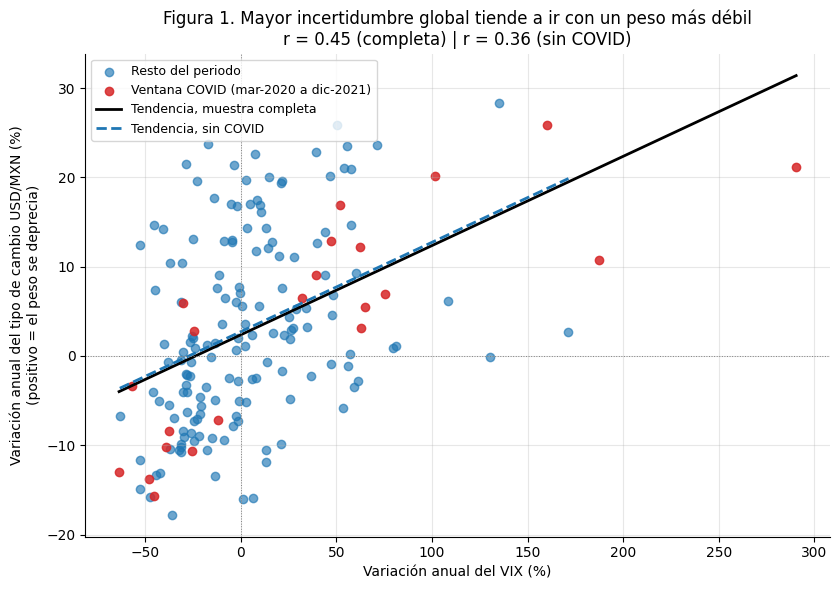

In [26]:
# Figura 1: ¿se mueven juntos el VIX y el tipo de cambio?
x, y = "RET_VIX_CIERRE", "RET_TC_CIERRE"
m = ret["COVID"]

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(ret.loc[~m, x], ret.loc[~m, y], alpha=0.65, color="tab:blue", label="Resto del periodo")
ax.scatter(ret.loc[m, x], ret.loc[m, y], alpha=0.85, color="tab:red", label="Ventana COVID (mar-2020 a dic-2021)")

for datos, color, estilo, nombre in [
    (ret, "black", "-", "Tendencia, muestra completa"),
    (sin_covid, "tab:blue", "--", "Tendencia, sin COVID"),
]:
    pendiente, ordenada = np.polyfit(datos[x], datos[y], 1)
    xs = np.linspace(datos[x].min(), datos[x].max(), 100)
    ax.plot(xs, pendiente * xs + ordenada, color=color, ls=estilo, lw=2, label=nombre)

ax.axhline(0, color="gray", lw=0.7, ls=":")
ax.axvline(0, color="gray", lw=0.7, ls=":")
ax.set_xlabel("Variación anual del VIX (%)")
ax.set_ylabel("Variación anual del tipo de cambio USD/MXN (%)\n(positivo = el peso se deprecia)")
ax.set_title(
    "Figura 1. Mayor incertidumbre global tiende a ir con un peso más débil\n"
    f"r = {ret[x].corr(ret[y]):.2f} (completa) | r = {sin_covid[x].corr(sin_covid[y]):.2f} (sin COVID)"
)
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_vix_vs_tipo_cambio.png", dpi=150, bbox_inches="tight")
plt.show()

**Cómo leer la Figura 1.** Cada punto es un mes. Si hubiera una relación positiva, los puntos se agruparían de la esquina inferior izquierda a la superior derecha: años en que el VIX sube más coinciden con años en que el dólar se encarece más frente al peso. Los puntos rojos son los meses de la ventana COVID; si las dos rectas de tendencia (completa y sin COVID) son parecidas, el patrón **no depende** de ese episodio. Los puntos muy alejados son meses extremos que conviene identificar, porque pueden tener un peso desproporcionado en la correlación.

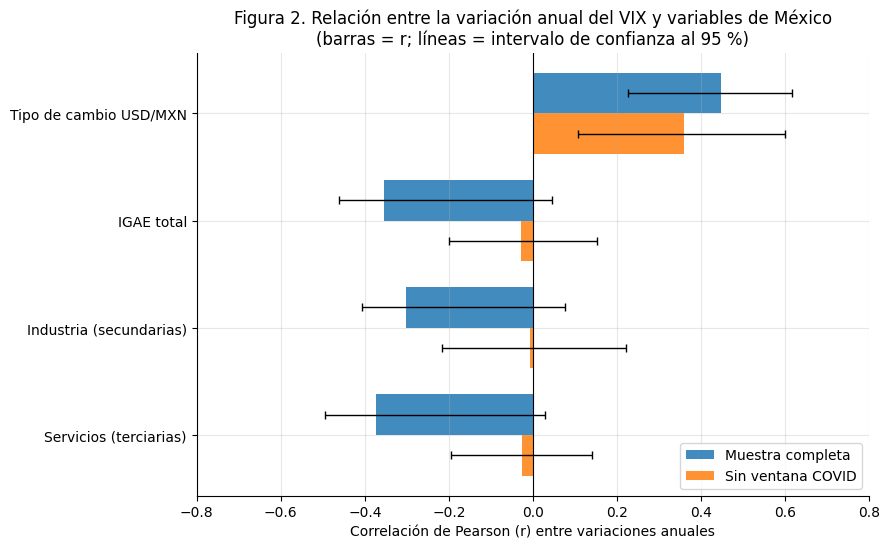

In [27]:
# Figura 2: sensibilidad de la economía mexicana frente al VIX
graf_corr(
    tab_vix_full, tab_vix_sin,
    "Figura 2. Relación entre la variación anual del VIX y variables de México\n"
    "(barras = r; líneas = intervalo de confianza al 95 %)",
    "fig2_vix_correlaciones.png",
)

**Cómo leer la Figura 2.** Cada barra es una correlación; la línea negra sobre la barra es su intervalo de confianza. Barras a la derecha del cero significan que las variables suben juntas; a la izquierda, que se mueven en sentido contrario. **Si la línea de error cruza el cero, no hay evidencia de relación.** Si la barra azul (completa) y la naranja (sin COVID) son similares, el resultado es robusto.

In [28]:
# Lectura del Hallazgo 1 con los números de esta corrida
def veredicto(r_full, lo, hi, r_sin):
    if lo <= 0 <= hi:
        return "no distinguible de cero"
    if np.sign(r_full) == np.sign(r_sin) and abs(r_sin) >= 0.7 * abs(r_full):
        return "robusta (se mantiene sin COVID)"
    if np.sign(r_full) == np.sign(r_sin):
        return "se debilita al excluir COVID"
    return "cambia de signo al excluir COVID"

print("LECTURA AUTOMÁTICA — HALLAZGO 1\n")
for col in Y_H1:
    nombre = ETIQ[col]
    f, s = tab_vix_full.loc[nombre], tab_vix_sin.loc[nombre]
    sentido = "al alza" if f["r"] > 0 else "a la baja"
    if f["ic95_inf"] <= 0 <= f["ic95_sup"]:
        lectura = "No se observa una relación clara (el intervalo incluye el 0); no afirmar asociación."
    else:
        lectura = f"Cuando el VIX sube, esta variable tiende a moverse {sentido}."
    print(f"- VIX vs. {nombre}: r = {f['r']:+.2f} (IC95 % [{f['ic95_inf']:+.2f}, {f['ic95_sup']:+.2f}]); "
          f"sin COVID r = {s['r']:+.2f}. {lectura} "
          f"Evidencia: {veredicto(f['r'], f['ic95_inf'], f['ic95_sup'], s['r'])}. "
          f"Variación compartida (r²): {f['r']**2:.0%}.")

LECTURA AUTOMÁTICA — HALLAZGO 1

- VIX vs. Tipo de cambio USD/MXN: r = +0.45 (IC95 % [+0.23, +0.62]); sin COVID r = +0.36. Cuando el VIX sube, esta variable tiende a moverse al alza. Evidencia: robusta (se mantiene sin COVID). Variación compartida (r²): 20%.
- VIX vs. IGAE total: r = -0.35 (IC95 % [-0.46, +0.05]); sin COVID r = -0.03. No se observa una relación clara (el intervalo incluye el 0); no afirmar asociación. Evidencia: no distinguible de cero. Variación compartida (r²): 12%.
- VIX vs. Industria (secundarias): r = -0.30 (IC95 % [-0.41, +0.08]); sin COVID r = -0.01. No se observa una relación clara (el intervalo incluye el 0); no afirmar asociación. Evidencia: no distinguible de cero. Variación compartida (r²): 9%.
- VIX vs. Servicios (terciarias): r = -0.37 (IC95 % [-0.50, +0.03]); sin COVID r = -0.03. No se observa una relación clara (el intervalo incluye el 0); no afirmar asociación. Evidencia: no distinguible de cero. Variación compartida (r²): 14%.


### Interpretación — Hallazgo 1 

| Relación con el VIX | r completa [IC95 %] | r sin COVID [IC95 %] | Spearman (completa / sin COVID) |
|---|---|---|---|
| Tipo de cambio USD/MXN | **+0.45** [+0.23, +0.62] | **+0.36** [+0.11, +0.60] | +0.49 / +0.41 |
| IGAE total | −0.35 [−0.46, +0.05] | −0.03 [−0.20, +0.15] | −0.21 / −0.02 |
| Industria | −0.30 [−0.41, +0.08] | −0.01 [−0.22, +0.22] | −0.19 / −0.01 |
| Servicios | −0.37 [−0.50, +0.03] | −0.03 [−0.19, +0.14] | −0.21 / −0.01 |

**1a. Tipo de cambio: hallazgo robusto.** En los años en que el VIX sube, el dólar tiende a encarecerse frente al peso. La relación es moderada (r² ≈ 20 %), su intervalo de confianza excluye el cero con y sin COVID, Spearman la confirma (0.49 y 0.41, así que no la producen unos pocos valores extremos) y en 93 % de las ventanas móviles de 24 meses es positiva (Figura 6). Dos matices: la relación no es constante (la correlación móvil cae a valores negativos alrededor de 2018 y llega a cerca de +0.9 en 2024-2025) y es una **asociación**, no una causa.

**1b. Actividad económica: la relación aparente se debe al COVID.** Con la muestra completa el VIX parece asociarse con menor crecimiento (r entre −0.30 y −0.37), pero **ni siquiera ahí** los intervalos excluyen el cero, y al quitar marzo 2020 a diciembre 2021 la correlación es prácticamente nula (entre −0.01 y −0.03). La correlación móvil frente al IGAE cambia de signo con frecuencia (negativa solo 48 % del tiempo). La explicación es simple: en 2020 el VIX se disparó y la actividad se desplomó al mismo tiempo, pero la causa de la caída fue el choque sanitario, no la volatilidad financiera. Este es un hallazgo en sí mismo: **no conviene atribuir al VIX una caída de la actividad que el análisis solo observa durante el COVID.** 

**Industria vs. servicios.** No hay diferencia distinguible entre ambos sectores; no afirma que uno sea más sensible que el otro.

## 4. Hallazgo 2 — ¿Cierre o promedio del S&P 500? La ventaja del promedio no se sostiene fuera del COVID

**Pregunta.** El pipeline conserva dos versiones del S&P 500: el **cierre** (valor del último día hábil) y el **promedio** de todo el mes. ¿Cuál se asocia más con el crecimiento económico de México?

**Por qué se plantea.** El IGAE mide actividad **acumulada durante el mes**; el cierre es la foto de un solo día. La hipótesis es que el promedio, al reflejar todo el mes, es más comparable con una variable de flujo. Este análisis pone a prueba esa decisión de diseño del dataset.

**Qué se calcula.** Correlación del IGAE total, industria y servicios con ambas versiones, y **la diferencia entre ambas** con su propio intervalo de confianza (si incluye el 0, la ventaja del promedio no es concluyente).

In [29]:
Y_H2 = ["RET_Total", "RET_Actividades secundarias", "RET_Actividades terciarias"]
SP_C, SP_P = "RET_SP500_CIERRE", "RET_SP500_PROMEDIO"

def tabla_h2(data):
    pares = [(y, s) for y in Y_H2 for s in (SP_C, SP_P)]
    boots = corr_bootstrap(data, pares)
    filas = []
    for y in Y_H2:
        r_c = data[y].corr(data[SP_C])
        r_p = data[y].corr(data[SP_P])
        dif = boots[(y, SP_P)] - boots[(y, SP_C)]
        lo, hi = np.nanpercentile(dif, [2.5, 97.5])
        filas.append({
            "variable": ETIQ[y], "r_cierre": r_c, "r_promedio": r_p,
            "diferencia (prom - cierre)": r_p - r_c,
            "dif_ic95_inf": lo, "dif_ic95_sup": hi,
            "dif_excluye_cero": not (lo <= 0 <= hi),
        })
    return pd.DataFrame(filas).set_index("variable")

h2_full = tabla_h2(ret)
h2_sin = tabla_h2(sin_covid)

comp_h2 = pd.concat({"Muestra completa": h2_full, "Sin ventana COVID": h2_sin}, axis=1).round(3)
comp_h2.to_csv(TAB_DIR / "h2_sp500_cierre_vs_promedio.csv")
comp_h2

Muestra completa             \
                                r_cierre r_promedio   
variable                                              
IGAE total                         0.138      0.251   
Industria (secundarias)            0.124      0.238   
Servicios (terciarias)             0.147      0.256   

                                                                              \
                        diferencia (prom - cierre) dif_ic95_inf dif_ic95_sup   
variable                                                                       
IGAE total                                   0.113        0.036        0.155   
Industria (secundarias)                      0.114        0.013        0.158   
Servicios (terciarias)                       0.109        0.045        0.152   

                                         Sin ventana COVID             \
                        dif_excluye_cero          r_cierre r_promedio   
variable                                                                
IGAE total                          True            -0.296     -0.256   
Industria (secundarias)             True            -0.359     -0.336   
Servicios (terciarias)              True            -0.216     -0.167   

                                                                              \
                        diferencia (prom - cierre) dif_ic95_inf dif_ic95_sup   
variable                                                                       
IGAE total                                   0.039       -0.011        0.090   
Industria (secundarias)                      0.023       -0.026        0.075   
Servicios (terciarias)                       0.050       -0.003        0.106   

                                          
                        dif_excluye_cero  
variable                                  
IGAE total                         False  
Industria (secundarias)            False  
Servicios (terciarias)             False

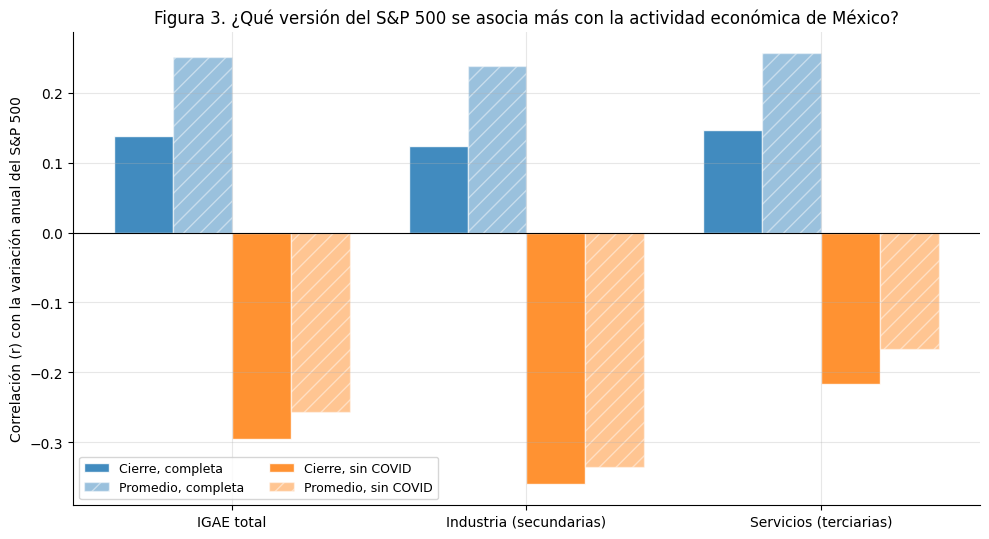

In [30]:
# Figura 3: cierre vs. promedio frente al crecimiento económico
etiquetas = h2_full.index.tolist()
pos = np.arange(len(etiquetas))
ancho = 0.2

fig, ax = plt.subplots(figsize=(10, 5.5))
series = [
    ("Cierre, completa", h2_full["r_cierre"], "tab:blue", 0.85),
    ("Promedio, completa", h2_full["r_promedio"], "tab:blue", 0.45),
    ("Cierre, sin COVID", h2_sin["r_cierre"], "tab:orange", 0.85),
    ("Promedio, sin COVID", h2_sin["r_promedio"], "tab:orange", 0.45),
]
for i, (nombre, valores, color, alfa) in enumerate(series):
    ax.bar(pos + (i - 1.5) * ancho, valores, width=ancho, color=color, alpha=alfa, label=nombre,
           hatch="//" if "Promedio" in nombre else None, edgecolor="white")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(pos)
ax.set_xticklabels(etiquetas)
ax.set_ylabel("Correlación (r) con la variación anual del S&P 500")
ax.set_title("Figura 3. ¿Qué versión del S&P 500 se asocia más con la actividad económica de México?")
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_sp500_cierre_vs_promedio.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
# [AUTO] Lectura automática del Hallazgo 2
print("LECTURA AUTOMÁTICA — HALLAZGO 2\n")
for nombre in h2_full.index:
    f, s = h2_full.loc[nombre], h2_sin.loc[nombre]
    concluyente = "la diferencia es estadísticamente distinguible de cero" if f["dif_excluye_cero"] \
        else "la diferencia NO es concluyente (el IC95 % de la diferencia incluye el 0)"
    print(f"- {nombre}: r(cierre) = {f['r_cierre']:+.2f}, r(promedio) = {f['r_promedio']:+.2f} "
          f"(diferencia {f['diferencia (prom - cierre)']:+.2f}, IC95 % [{f['dif_ic95_inf']:+.2f}, {f['dif_ic95_sup']:+.2f}]); "
          f"{concluyente}. Sin COVID: r(cierre) = {s['r_cierre']:+.2f}, r(promedio) = {s['r_promedio']:+.2f}.")
    if np.sign(f["r_promedio"]) != np.sign(s["r_promedio"]):
        print("    ADVERTENCIA: el signo de la correlación cambia al excluir COVID; la relación de la muestra completa no es estable.")
    if not s["dif_excluye_cero"]:
        print("    Sin COVID la ventaja del promedio sobre el cierre ya no es distinguible de cero.")

LECTURA AUTOMÁTICA — HALLAZGO 2

- IGAE total: r(cierre) = +0.14, r(promedio) = +0.25 (diferencia +0.11, IC95 % [+0.04, +0.16]); la diferencia es estadísticamente distinguible de cero. Sin COVID: r(cierre) = -0.30, r(promedio) = -0.26.
    ADVERTENCIA: el signo de la correlación cambia al excluir COVID; la relación de la muestra completa no es estable.
    Sin COVID la ventaja del promedio sobre el cierre ya no es distinguible de cero.
- Industria (secundarias): r(cierre) = +0.12, r(promedio) = +0.24 (diferencia +0.11, IC95 % [+0.01, +0.16]); la diferencia es estadísticamente distinguible de cero. Sin COVID: r(cierre) = -0.36, r(promedio) = -0.34.
    ADVERTENCIA: el signo de la correlación cambia al excluir COVID; la relación de la muestra completa no es estable.
    Sin COVID la ventaja del promedio sobre el cierre ya no es distinguible de cero.
- Servicios (terciarias): r(cierre) = +0.15, r(promedio) = +0.26 (diferencia +0.11, IC95 % [+0.04, +0.15]); la diferencia es estadísticament

### Interpretación — Hallazgo 2 (con los resultados de la corrida)

| Frente a... | r cierre | r promedio | Diferencia [IC95 %] | Sin COVID: r cierre / r promedio | Sin COVID: diferencia [IC95 %] |
|---|---|---|---|---|---|
| IGAE total | +0.14 | +0.25 | +0.11 [+0.04, +0.16] | −0.30 / −0.26 | +0.04 [−0.01, +0.09] |
| Industria | +0.12 | +0.24 | +0.11 [+0.01, +0.16] | −0.36 / −0.34 | +0.02 [−0.03, +0.08] |
| Servicios | +0.15 | +0.26 | +0.11 [+0.04, +0.15] | −0.22 / −0.17 | +0.05 [−0.00, +0.11] |

**Lectura.** En la muestra completa el promedio queda por encima del cierre y la diferencia (+0.11) sí es distinguible de cero. Pero ese resultado **no se sostiene** por tres razones:
1. **Sin COVID la ventaja se desvanece**: la diferencia baja a entre +0.02 y +0.05 y sus intervalos incluyen el cero (en servicios apenas lo rozan).
2. **El signo de la relación cambia.** Con la muestra completa la correlación con la actividad es positiva (+0.25) y sin COVID es **negativa** (−0.26). Una relación que invierte su signo al quitar un episodio no es una relación estable; la positiva de la muestra completa proviene de 2020, cuando la bolsa y la actividad cayeron y rebotaron en el mismo periodo.
3. **Ninguna correlación individual es distinguible de cero** en la muestra completa (por ejemplo, promedio vs. IGAE total: IC95 % [−0.29, +0.51], según la tabla resumen). Que una correlación débil sea "un poco mayor" que otra igual de débil no aporta mucho.

**Qué sí se puede decir.** Cierre y promedio dan resultados casi equivalentes, y este análisis **no demuestra** que el promedio sea mejor. Conservar `SP500_PROMEDIO` sigue siendo una decisión de diseño razonable por coherencia temporal (variable de flujo mensual frente a un indicador mensual), pero la justificación es conceptual, no empírica. 

**Qué no se puede decir.** Que el S&P 500 se asocie positivamente con la actividad económica de México, o que "explique" parte de ella. Fuera del COVID, el signo es incluso el contrario y con intervalos

## 5. Hallazgo 3 (secundario) — Tipo de cambio e inflación: ¿hay traspaso rezagado?

**Pregunta.** La teoría económica sugiere que un peso más débil encarece los productos importados y presiona la inflación (efecto **traspaso** o *pass-through*). Pero el notebook 04 encontró una correlación **negativa** (aprox. −0.46) entre depreciación e inflación **en el mismo mes**, lo contrario a lo esperado.

**Explicación (no a asumir).** El traspaso no es inmediato: los precios tardan meses en ajustarse. Si es así, la relación debería aparecer **al comparar la depreciación de hace *k* meses con la inflación de hoy**. La siguiente gráfica calcula esa correlación para rezagos de 0 a 24 meses.

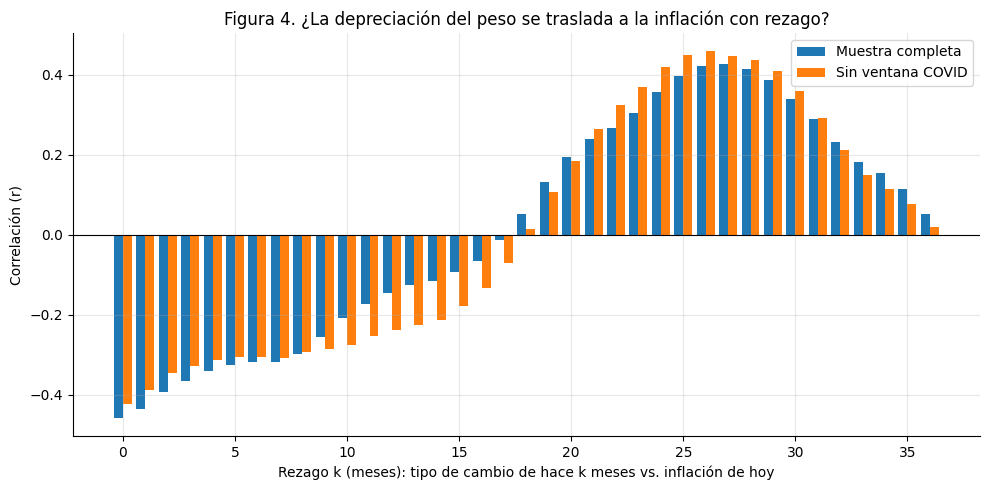

Rezago 0 (mismo mes)        : r = -0.46
Rezago con mayor r positivo  : k = 27 meses, r = +0.43
Rezago con menor r (más neg.): k = 0 meses, r = -0.46


In [32]:
RET_TC, RET_INF = "RET_TC_CIERRE", "RET_INPC"
rezagos = range(0, 37)

def corr_rezago(data, k):
    """Correlación entre el TC de hace k meses y la inflación actual (filas ya filtradas)."""
    return data[RET_TC].shift(k).corr(data[RET_INF])

# Muestra completa: se desplaza sobre la serie continua
cc_full = pd.Series({k: corr_rezago(ret, k) for k in rezagos})

# Sin COVID: se desplaza sobre la serie completa y luego se descartan los meses de la ventana
cc_sin = pd.Series({
    k: ret[RET_TC].shift(k)[~ret["COVID"]].corr(ret[RET_INF][~ret["COVID"]]) for k in rezagos
})

fig, ax = plt.subplots(figsize=(10, 5))
ancho = 0.4
ax.bar(np.array(list(rezagos)) - ancho / 2, cc_full.values, width=ancho, color="tab:blue", label="Muestra completa")
ax.bar(np.array(list(rezagos)) + ancho / 2, cc_sin.values, width=ancho, color="tab:orange", label="Sin ventana COVID")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Rezago k (meses): tipo de cambio de hace k meses vs. inflación de hoy")
ax.set_ylabel("Correlación (r)")
ax.set_title("Figura 4. ¿La depreciación del peso se traslada a la inflación con rezago?")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_traspaso_rezagos.png", dpi=150, bbox_inches="tight")
plt.show()

mejor_full = cc_full.idxmax()
print(f"Rezago 0 (mismo mes)        : r = {cc_full[0]:+.2f}")
print(f"Rezago con mayor r positivo  : k = {mejor_full} meses, r = {cc_full[mejor_full]:+.2f}")
print(f"Rezago con menor r (más neg.): k = {cc_full.idxmin()} meses, r = {cc_full.min():+.2f}")

In [33]:
# Lectura del Hallazgo 3
primer_positivo = next((k for k in rezagos if cc_full[k] > 0), None)
k_max = int(cc_full.idxmax())
borde = max(rezagos)

print("LECTURA AUTOMÁTICA — HALLAZGO 3\n")
print(f"- Mismo mes (k = 0): r = {cc_full[0]:+.2f} (sin COVID: {cc_sin[0]:+.2f}).")
if primer_positivo is None:
    print("- La correlación es negativa en todos los rezagos evaluados: no se observa traspaso visible.")
else:
    print(f"- La correlación es negativa hasta k = {primer_positivo - 1} y positiva desde k = {primer_positivo}; "
          f"el máximo (r = {cc_full[k_max]:+.2f}) está en k = {k_max}.")
    if k_max >= borde - 1:
        print("- OJO: el máximo cae en el borde del rango evaluado; la relación sigue creciendo y no se puede ubicar un pico.")
    if primer_positivo > 12:
        print("- Un efecto que solo aparece después de más de 12 meses no es el traspaso gradual típico (meses). "
              "Interprétalo como posible ciclo compartido entre series, no como traspaso.")
    elif 3 <= k_max <= 12 and cc_full[k_max] > 0.2:
        print(f"- Hay una relación positiva con rezago de {k_max} meses, compatible con un traspaso gradual (no es prueba).")
print("- No se calcularon intervalos de confianza por rezago: no afirmes significancia para un rezago puntual.")

LECTURA AUTOMÁTICA — HALLAZGO 3

- Mismo mes (k = 0): r = -0.46 (sin COVID: -0.42).
- La correlación es negativa hasta k = 17 y positiva desde k = 18; el máximo (r = +0.43) está en k = 27.
- Un efecto que solo aparece después de más de 12 meses no es el traspaso gradual típico (meses). Interprétalo como posible ciclo compartido entre series, no como traspaso.
- No se calcularon intervalos de confianza por rezago: no afirmes significancia para un rezago puntual.


### Interpretación — Hallazgo 3 (con los resultados de la corrida)

**Qué muestran los datos.** La correlación entre depreciación del peso e inflación es **negativa en el mismo mes** (r = −0.46, IC95 % [−0.67, −0.26]; −0.42 sin COVID) y se mantiene negativa durante unos 17 rezagos mensuales. Solo cruza a positiva alrededor de los 18 meses y sigue subiendo hasta el final del rango que se evaluó inicialmente (24 meses; en esta versión se extiende a 36 para ver si alcanza un máximo).

**Qué NO se puede decir.**
* Que el traspaso aparezca "con rezago de 24 meses". El traspaso típico se mide en meses, no en dos años, y una correlación que sigue creciendo en el borde del rango no identifica un pico.
* Que exista traspaso en el horizonte de 0 a 12 meses: ahí la correlación es negativa, lo contrario de lo que predice la teoría.
* Ninguno de los rezagos tiene intervalo de confianza calculado.

**Hipótesis (sin comprobar) para la relación negativa.** Hubo periodos de inflación alta con peso fuerte (2021-2023) y depreciaciones con inflación moderada; las variaciones a 12 meses se traslapan y unos pocos episodios largos dominan la correlación. La parte positiva a 18-24 meses podría reflejar ciclos largos compartidos entre las series más que un mecanismo de traspaso.

**Cómo presentarlo.** Es un hallazgo secundario: "con las series mensuales disponibles no se observa un traspaso visible del tipo de cambio a la inflación en horizontes de hasta un año y medio; la relación contemporánea es incluso negativa, lo que probablemente refleja factores no controlados (alimentos, energía, política monetaria)". 

## 6. Hallazgo en negativo — Las finanzas públicas reales no se mueven con el entorno financiero

También es un resultado informativo **encontrar que no hay relación**. Se evalúa si el crecimiento real de ingresos y gastos del Gobierno Federal se asocia con el VIX, el S&P 500 promedio o el tipo de cambio.

In [34]:
Y_FISC = ["RET_INGRESOS_REALES", "RET_GASTOS_REALES"]
X_FISC = ["RET_VIX_CIERRE", "RET_SP500_PROMEDIO", "RET_TC_CIERRE"]

filas = []
for x in X_FISC:
    t_full = tabla_corr(ret, x, Y_FISC)
    t_sin = tabla_corr(sin_covid, x, Y_FISC)
    for v in Y_FISC:
        n = ETIQ[v]
        filas.append({
            "factor externo": ETIQ[x], "variable fiscal": n,
            "r (completa)": t_full.loc[n, "r"], "IC95 inf": t_full.loc[n, "ic95_inf"], "IC95 sup": t_full.loc[n, "ic95_sup"],
            "IC excluye 0": t_full.loc[n, "ic_excluye_cero"], "r (sin COVID)": t_sin.loc[n, "r"],
        })
tab_fiscal = pd.DataFrame(filas).round(3)
tab_fiscal.to_csv(TAB_DIR / "h4_finanzas_publicas.csv", index=False)
display(tab_fiscal)

print("\nVariabilidad del crecimiento anual (%):")
display(ret[Y_FISC].describe().loc[["mean", "std", "min", "max"]].rename(columns=ETIQ).round(1))

,factor externo,variable fiscal,r (completa),IC95 inf,IC95 sup,IC excluye 0,r (sin COVID)
0,VIX (incertidumbre global),Ingresos reales del Gobierno,-0.023,-0.121,0.076,False,0.010
1,VIX (incertidumbre global),Gastos reales del Gobierno,-0.017,-0.147,0.119,False,-0.036
2,S&P 500 (promedio del mes),Ingresos reales del Gobierno,0.022,-0.072,0.140,False,0.005
3,S&P 500 (promedio del mes),Gastos reales del Gobierno,0.002,-0.076,0.114,False,0.025
4,Tipo de cambio USD/MXN,Ingresos reales del Gobierno,0.071,-0.075,0.165,False,0.132
5,Tipo de cambio USD/MXN,Gastos reales del Gobierno,-0.004,-0.121,0.127,False,0.000



Variabilidad del crecimiento anual (%):


,Ingresos reales del Gobierno,Gastos reales del Gobierno
mean,3.5,4.3
std,16.5,13.7
min,-53.0,-36.4
max,104.0,58.9


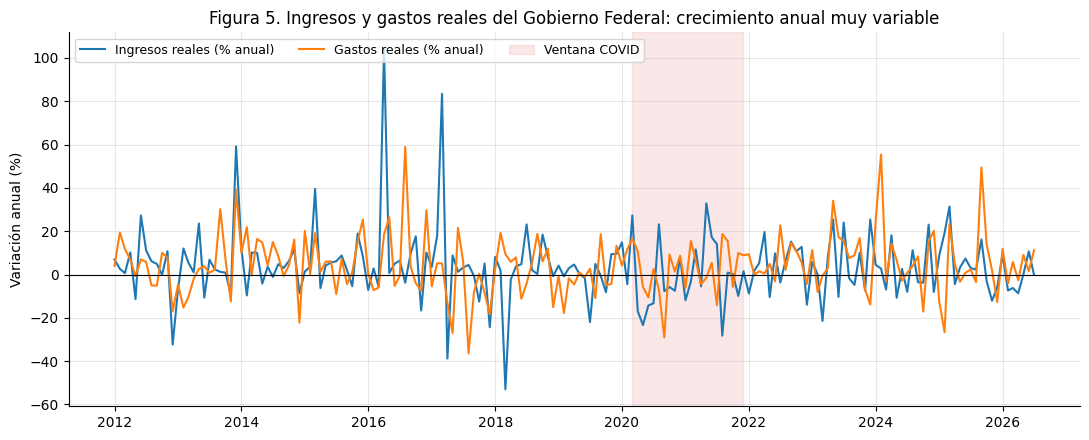

In [35]:
# Figura 5: volatilidad del crecimiento de ingresos y gastos reales
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ret["PERIODO"], ret["RET_INGRESOS_REALES"], color="tab:blue", lw=1.5, label="Ingresos reales (% anual)")
ax.plot(ret["PERIODO"], ret["RET_GASTOS_REALES"], color="tab:orange", lw=1.5, label="Gastos reales (% anual)")
sombrear_covid(ax)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Variación anual (%)")
ax.set_title("Figura 5. Ingresos y gastos reales del Gobierno Federal: crecimiento anual muy variable")
ax.legend(loc="upper left", ncol=3, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_finanzas_publicas.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación de referencia — Finanzas públicas
*(En 04 y 05 las correlaciones de ingresos y gastos reales con el VIX, el S&P 500 y el tipo de cambio fueron prácticamente nulas, entre aprox. −0.03 y +0.07.)*

**Lectura.** El crecimiento real de los ingresos y gastos del Gobierno Federal **no sigue** a los mercados financieros de EE.UU. ni al tipo de cambio. Además, las series son **muy volátiles** (los ingresos reales llegan a variaciones anuales de más de ±50 %), de modo que la ausencia de correlación puede deberse a ruido, a **ingresos extraordinarios o no recurrentes** o a decisiones de política fiscal que responden a otros factores. Con estos datos **no se puede concluir** que las finanzas públicas sean insensibles al entorno global, solo que **no se observa** una relación lineal con estas variables.

Es un buen ejemplo para la sección de limitaciones: *"que no encontremos relación no prueba que no exista"*.

## 7. Pruebas de robustez

Un hallazgo es creíble cuando se sostiene bajo distintas formas de medirlo. Se hacen dos chequeos adicionales:

1. **Estabilidad en el tiempo (correlación móvil de 24 meses).** ¿La relación VIX–tipo de cambio es persistente, o aparece solo en unos pocos episodios?
2. **Correlación de rangos (Spearman).** La variación del VIX es muy asimétrica (con picos de cientos de por ciento). Spearman usa solo el **orden** de los datos, por lo que no se distorsiona por valores extremos.

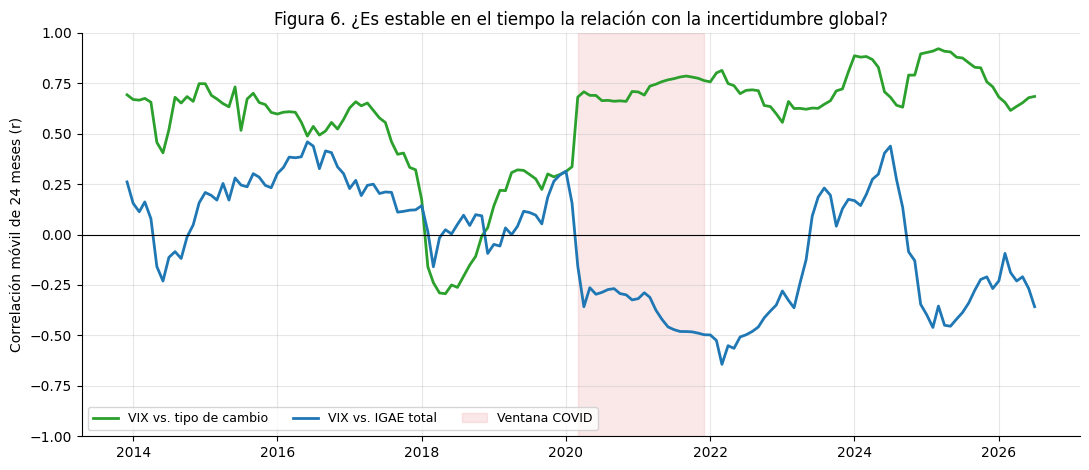

 VIX–tipo de cambio fue positiva en 93% de las ventanas de 24 meses.
 VIX–IGAE total fue negativa en 48% de las ventanas de 24 meses.


In [36]:
s = ret.set_index("PERIODO")
rodante_tc = s["RET_VIX_CIERRE"].rolling(24).corr(s["RET_TC_CIERRE"])
rodante_igae = s["RET_VIX_CIERRE"].rolling(24).corr(s["RET_Total"])

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(rodante_tc.index, rodante_tc, color="tab:green", lw=2, label="VIX vs. tipo de cambio")
ax.plot(rodante_igae.index, rodante_igae, color="tab:blue", lw=2, label="VIX vs. IGAE total")
sombrear_covid(ax)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-1, 1)
ax.set_ylabel("Correlación móvil de 24 meses (r)")
ax.set_title("Figura 6. ¿Es estable en el tiempo la relación con la incertidumbre global?")
ax.legend(loc="lower left", ncol=3, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_correlacion_movil_vix.png", dpi=150, bbox_inches="tight")
plt.show()

pct_pos_tc = (rodante_tc.dropna() > 0).mean()
pct_neg_igae = (rodante_igae.dropna() < 0).mean()
print(f" VIX–tipo de cambio fue positiva en {pct_pos_tc:.0%} de las ventanas de 24 meses.")
print(f" VIX–IGAE total fue negativa en {pct_neg_igae:.0%} de las ventanas de 24 meses.")

In [37]:
cols_spearman = ["RET_TC_CIERRE", "RET_Total", "RET_Actividades secundarias", "RET_Actividades terciarias"]

def spearman_pd(df, col_x, col_y):
    return df[col_x].rank().corr(df[col_y].rank())

comparativa = pd.DataFrame({
    "Pearson (completa)": [ret["RET_VIX_CIERRE"].corr(ret[c]) for c in cols_spearman],
    "Spearman (completa)": [spearman_pd(ret, "RET_VIX_CIERRE", c) for c in cols_spearman],
    "Pearson (sin COVID)": [sin_covid["RET_VIX_CIERRE"].corr(sin_covid[c]) for c in cols_spearman],
    "Spearman (sin COVID)": [spearman_pd(sin_covid, "RET_VIX_CIERRE", c) for c in cols_spearman],
}, index=[ETIQ[c] for c in cols_spearman]).round(3)

comparativa.to_csv(TAB_DIR / "robustez_pearson_vs_spearman.csv")
comparativa

,Pearson (completa),Spearman (completa),Pearson (sin COVID),Spearman (sin COVID)
Tipo de cambio USD/MXN,0.448,0.490,0.359,0.411
IGAE total,-0.353,-0.213,-0.029,-0.018
Industria (secundarias),-0.301,-0.190,-0.006,-0.014
Servicios (terciarias),-0.373,-0.207,-0.025,-0.012


### Interpretación — Robustez 
* **Correlación móvil (Figura 6).** VIX vs. tipo de cambio es positiva en 93 % de las ventanas de 24 meses: el patrón es persistente, aunque su intensidad varía mucho (de cerca de −0.3 alrededor de 2018 a cerca de +0.9 en 2024-2025). VIX vs. IGAE total es negativa solo en 48 % de las ventanas y cambia de signo varias veces: **no hay una relación estable con la actividad**, lo que confirma el Hallazgo 1b.
* **Spearman vs. Pearson.** Para el tipo de cambio, Spearman (0.49 y 0.41) es incluso mayor que Pearson (0.45 y 0.36): la relación no depende de valores extremos como el VIX de 2020. Para la actividad, Spearman es de −0.19 a −0.21 con la muestra completa y cercano a cero sin COVID: ratifica que lo observado en la muestra completa viene del COVID.

## 8. Tabla resumen de hallazgos
Consolida los indicadores principales con su veredicto de robustez. 

In [38]:
RESUMEN = [
    ("H1", "VIX", "RET_VIX_CIERRE", "RET_TC_CIERRE"),
    ("H1", "VIX", "RET_VIX_CIERRE", "RET_Total"),
    ("H1", "VIX", "RET_VIX_CIERRE", "RET_Actividades terciarias"),
    ("H1", "VIX", "RET_VIX_CIERRE", "RET_Actividades secundarias"),
    ("H2", "S&P 500 promedio", "RET_SP500_PROMEDIO", "RET_Total"),
    ("H2", "S&P 500 cierre", "RET_SP500_CIERRE", "RET_Total"),
    ("H3", "Tipo de cambio (mismo mes)", "RET_TC_CIERRE", "RET_INPC"),
    ("Fiscal", "VIX", "RET_VIX_CIERRE", "RET_INGRESOS_REALES"),
    ("Fiscal", "Tipo de cambio", "RET_TC_CIERRE", "RET_GASTOS_REALES"),
]
pares = [(x, y) for (_, _, x, y) in RESUMEN]
b_full = corr_bootstrap(ret, pares)

filas = []
for (hall, nombre_x, x, y) in RESUMEN:
    r_f = ret[x].corr(ret[y])
    r_s = sin_covid[x].corr(sin_covid[y])
    lo, hi = np.nanpercentile(b_full[(x, y)], [2.5, 97.5])
    filas.append({
        "Hallazgo": hall, "Factor": nombre_x, "Variable en México": ETIQ[y],
        "r (completa)": r_f, "IC95 %": f"[{lo:+.2f}, {hi:+.2f}]",
        "r (sin COVID)": r_s, "r²": r_f ** 2, "Veredicto": veredicto(r_f, lo, hi, r_s),
    })
tabla_resumen = pd.DataFrame(filas).round(3)
tabla_resumen.to_csv(TAB_DIR / "resumen_hallazgos.csv", index=False)
tabla_resumen

,Hallazgo,Factor,Variable en México,r (completa),IC95 %,r (sin COVID),r²,Veredicto
0,H1,VIX,Tipo de cambio USD/MXN,0.448,"[+0.23, +0.62]",0.359,0.201,robusta (se mantiene sin COVID)
1,H1,VIX,IGAE total,-0.353,"[-0.46, +0.05]",-0.029,0.125,no distinguible de cero
2,H1,VIX,Servicios (terciarias),-0.373,"[-0.50, +0.03]",-0.025,0.139,no distinguible de cero
3,H1,VIX,Industria (secundarias),-0.301,"[-0.41, +0.08]",-0.006,0.091,no distinguible de cero
4,H2,S&P 500 promedio,IGAE total,0.251,"[-0.29, +0.51]",-0.256,0.063,no distinguible de cero
5,H2,S&P 500 cierre,IGAE total,0.138,"[-0.34, +0.41]",-0.296,0.019,no distinguible de cero
6,H3,Tipo de cambio (mismo mes),Inflación (INPC),-0.457,"[-0.67, -0.26]",-0.421,0.209,robusta (se mantiene sin COVID)
7,Fiscal,VIX,Ingresos reales del Gobierno,-0.023,"[-0.12, +0.08]",0.010,0.001,no distinguible de cero
8,Fiscal,Tipo de cambio,Gastos reales del Gobierno,-0.004,"[-0.12, +0.13]",0.000,0.000,no distinguible de cero


Los hallazgos que se presenten como principales deben tener veredicto **"robusta"**. Los que digan "no distinguible de cero" se reportan como ausencia de evidencia; los que digan "se debilita" o "cambia de signo" llevan una advertencia explícita sobre COVID.

## 9. Limitaciones y alcance de las conclusiones

La guía pide señalar explícitamente los límites del análisis. Estas son las que aplican aquí:

| Limitación | Por qué importa | Cómo se mitigó |
|---|---|---|
| **Correlación no es causalidad** | Dos variables pueden moverse juntas por un tercer factor (tasas de interés, petróleo, política monetaria) que no está en el dataset. | Se usa lenguaje de asociación ("tiende a", "se asocia con"), nunca de causa. |
| **Ventanas de 12 meses traslapadas** | Las observaciones consecutivas comparten 11 meses de información; la muestra efectiva es menor a 175. | Intervalos de confianza por bootstrap de bloques de 12 meses. |
| **Periodo COVID** | Marzo 2020 y el efecto base de 2021 generan valores extremos que pueden dominar una correlación. | Cada resultado se reporta con y sin esa ventana. |
| **Cobertura temporal** | Enero 2011 a julio 2026: 187 meses; el último año es parcial. Pocos ciclos económicos completos. | Se documenta; no se extrapola. |
| **Magnitud de las relaciones** | La mayoría de las correlaciones están entre 0.2 y 0.5 (r² de 4 % a 20 %). | Se reporta r² y se evita hablar de "determina" o "explica". |
| **Relaciones solo lineales** | Pearson no captura relaciones no lineales ni efectos que solo aparecen en crisis. | Se contrasta con Spearman y con correlación móvil; no se modelan no linealidades. |
| **Sin variables de control** | No se aísla el efecto del VIX de otros factores simultáneos. | Se declara explícitamente; un modelo multivariado queda como trabajo futuro. |
| **Calidad y supuestos del dato** | Los ingresos y gastos reales dependen del deflactor INPC (base dic-2025) y pueden contener partidas extraordinarias. | Se interpretan con cautela y se presenta su volatilidad (Figura 5). |
| **Pruebas múltiples** | Al revisar muchas correlaciones, alguna puede salir "llamativa" por azar. | Los hallazgos principales son pocos, definidos antes de ver los resultados y evaluados con intervalo de confianza. |

**Lo que NO se puede concluir con estos datos**
* Que el VIX *cause* depreciaciones del peso o caídas de la actividad.
* Que la industria sea más sensible que los servicios al entorno global.
* Que un peso débil eleve la inflación.
* Que las finanzas públicas sean independientes del entorno global.
* Cualquier pronóstico: el análisis es descriptivo del pasado.

## 10. Conclusiones para una audiencia no especializada

Entre 2012 y 2026, el vínculo más claro y estable entre el nerviosismo de los mercados de EE.UU. y México es el **tipo de cambio**: en los años en que aumenta la incertidumbre global (VIX), el dólar tiende a encarecerse frente al peso. En cambio, **no se encontró evidencia de que esa incertidumbre, o el S&P 500, se asocien con el crecimiento de la economía mexicana fuera del periodo COVID**.

**Hallazgo 1 — Incertidumbre global y peso (robusto).** La relación es moderada (el VIX comparte alrededor de una quinta parte de la variación del tipo de cambio), se mantiene al excluir el periodo COVID (r de 0.45 a 0.36) y es positiva en 93 % de las ventanas móviles de dos años, aunque su intensidad cambia con el tiempo. Es una asociación, no una prueba de causa.

**Hallazgo 2 — La caída de la actividad en 2020 no debe atribuirse a la volatilidad financiera.** En la muestra completa parece que el VIX y el crecimiento económico se mueven en sentido contrario, pero esa relación desaparece al excluir marzo 2020 a diciembre 2021 (correlación cercana a cero). La actividad cayó por el choque sanitario, no porque el VIX subiera.

**Hallazgos complementarios.**
* **S&P 500 (cierre o promedio):** ambas versiones se comportan casi igual; la ventaja del promedio no se sostiene fuera del COVID y la relación con la actividad cambia de signo. No es concluyente.
* **Tipo de cambio e inflación:** no se observa un traspaso visible en horizontes de hasta aproximadamente año y medio; la relación del mismo mes es negativa, probablemente por factores no controlados.
* **Finanzas públicas reales:** ingresos y gastos no muestran relación con el entorno financiero global; las series son muy volátiles (con picos que podrían deberse a ingresos extraordinarios), así que el resultado es informativo, no concluyente.

**Para quién es útil.** Para entender que la exposición de México a los sobresaltos financieros de EE.UU. se ve sobre todo en el **tipo de cambio**, mientras que en la actividad económica el análisis no detecta una conexión estable, y como punto de partida para estudios con controles.

**Lo que sigue (trabajo futuro, no implementado).** Un modelo multivariado con controles (tasas de interés, petróleo, remesas), intervalos de confianza por rezago, y la incorporación de nuevas fuentes mediante el pipeline modular existente.

## 11. Evidencias guardadas y lista de verificación
La celda siguiente enumera lo que quedó guardado para enlazar desde el README y el Pull Request.

In [39]:
print("Figuras guardadas en", FIG_DIR)
for p in sorted(FIG_DIR.glob("fig*.png")):
    print("  -", p.name)
print("\nTablas guardadas en", TAB_DIR)
for p in sorted(TAB_DIR.glob("*.csv")):
    print("  -", p.name)

Figuras guardadas en reports/figures
  - fig1_vix_vs_tipo_cambio.png
  - fig2_vix_correlaciones.png
  - fig3_sp500_cierre_vs_promedio.png
  - fig4_traspaso_rezagos.png
  - fig5_finanzas_publicas.png
  - fig6_correlacion_movil_vix.png

Tablas guardadas en reports/tablas_etapa_c
  - h1_vix_correlaciones.csv
  - h2_sp500_cierre_vs_promedio.csv
  - h4_finanzas_publicas.csv
  - resumen_hallazgos.csv
  - robustez_pearson_vs_spearman.csv
